In [1]:
import numpy as np
import pandas as pd
from scipy.stats import chi2
from scipy.stats import f
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.diagnostic import het_arch
from statsmodels.stats.stattools import jarque_bera

import matplotlib.pyplot as plt

from s_master import (VARlsExog, lagmatrix, march, multnorm,
                      jcitestexog, johcontest, vec)

import sys; print(sys.executable)   # skal ende på \envs\svar\python.exe

df = pd.read_excel("VARSWE.xls", skiprows=5)

# The first column holds the dates but has no name in the file, so we name it.
df = df.rename(columns={df.columns[0]: "Dates"})

df.head()

c:\Users\niels\anaconda3\envs\svar\python.exe


,Dates,GDP,r,CPISA,FED,RERinv,Aldp,du93Q1,du95Q4,du92Q3,du92Q4,du1993,rtwi,OILP,du86Q1,du9091
0,1982-01-01,1445045.9,12.34,45.463,14.226667,0.008315,0.086278,0,0,0,0,0,13.854583,32.277890,0,0
1,1982-04-01,1470421.9,13.03,46.242,14.513333,0.008338,0.082034,0,0,0,0,0,13.766667,34.309670,0,0
2,1982-07-01,1454215.5,14.36,46.907,11.006667,0.008295,0.075245,0,0,0,0,0,11.274583,33.592934,0,0
3,1982-10-01,1483632.4,13.27,48.070,9.286667,0.009484,0.085450,0,0,0,0,0,9.652083,33.513588,0,0
4,1983-01-01,1463891.4,11.13,49.425,8.653333,0.009583,0.083558,0,0,0,0,0,9.420417,29.392778,0,0


In [2]:
y = np.log(df["GDP"]).rename("y")

#pi = (np.log(df["CPISA"]) - np.log(df["CPISA"].shift(4))).rename("pi")

pi = (df["CPISA"] / df["CPISA"].shift(4) - 1).rename("pi")     # [ÆNDRET] procentvis ændring som facit

i = df["r"].rename("i")

i_star = df["rtwi"].rename("i_star")

lrexc = np.log(df["RERinv"])
de = (lrexc - lrexc.shift(1)).rename("de")

#assert np.allclose(pi.dropna(), df["Aldp"][pi.notna()], atol=1e-6)

DUMMIES = ["du93Q1", "du92Q3", "du95Q4"]

result = pd.concat([df["Dates"], y, pi, i, i_star, de, df[DUMMIES]], axis=1)

result = result.dropna().reset_index(drop=True)

# The assignment sample is 1983Q1 to 2004Q4
print(len(result), "observations, from",
      result["Dates"].iloc[0].date(), "to", result["Dates"].iloc[-1].date())

#Show the data
result

88 observations, from 1983-01-01 to 2004-10-01


,Dates,y,pi,i,i_star,de,du93Q1,du92Q3,du95Q4
0,1983-01-01,14.196609,0.087148,11.13,9.420417,0.010391,0,0,0
1,1983-04-01,14.207326,0.086804,10.98,9.165417,-0.012381,0,0,0
2,1983-07-01,14.216993,0.092097,11.45,9.448750,-0.017080,0,0,0
3,1983-10-01,14.237927,0.088808,12.09,9.388750,-0.009262,0,0,0
4,1984-01-01,14.262249,0.084047,11.00,9.457083,-0.011914,0,0,0
...,...,...,...,...,...,...,...,...,...
83,2003-10-01,14.660120,0.012847,2.72,2.000833,-0.026818,0,0,0
84,2004-01-01,14.668892,0.000600,2.47,2.044167,0.016827,0,0,0
85,2004-04-01,14.678635,0.004067,2.00,2.152500,0.011919,0,0,0
86,2004-07-01,14.686129,0.005650,1.99,2.459167,0.002646,0,0,0


### Q1 
Plot the transformed time series and compare to the graphs in Bjørnland. Are these
time series stationary? Is there a linear trend? Provide descriptive statistics such as
mean, median, min, max, number of observations and standard deviations in a table.

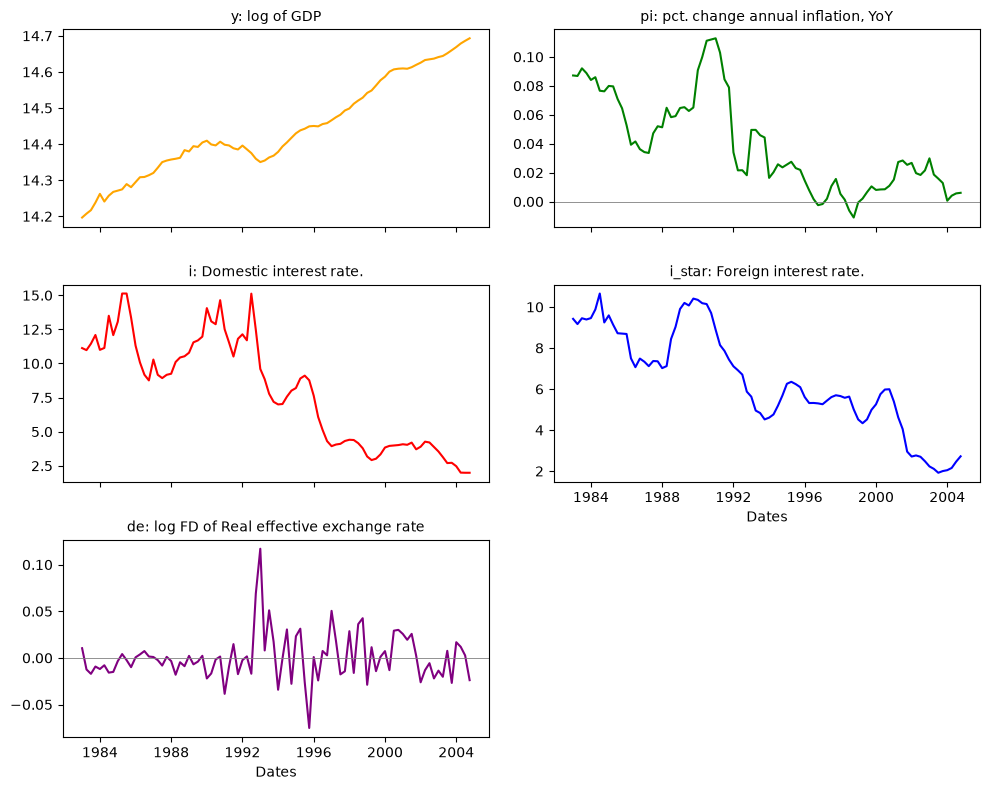

In [3]:
series = [
    
    ("y",      "y: log of GDP",                              "orange", False),
    ("pi",     "pi: pct. change annual inflation, YoY",             "green",  True),
    ("i",      "i: Domestic interest rate.",             "red",    False),
    ("i_star", "i_star: Foreign interest rate.",      "blue",   False),
    ("de",     "de: log FD of Real effective exchange rate",       "purple", True),
    ]
    
fig, axs = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
fig.delaxes(axs[2, 1])  # five variables, six panels

panels = [axs[0, 0], axs[0, 1], axs[1, 0], axs[1, 1], axs[2, 0]]
for ax, (col, title, colour, zero_line) in zip(panels, series):
    ax.plot(result["Dates"], result[col], color=colour)
    ax.set_title(title, fontsize=10)
    if zero_line:
        # only for the series measured as changes, where zero is meaningful
        ax.axhline(0, lw=0.6, color="grey")

# sharex hides tick labels above the bottom row, but axs[2, 1] is gone, so put
# the labels back on the lowest panel that is actually still visible.
axs[1, 1].tick_params(labelbottom=True)
for ax in (axs[1, 1], axs[2, 0]):
    ax.set_xlabel("Dates")

plt.tight_layout()
plt.show()

In [4]:
#Otherwise, we can manually denote which stats to calculate, like so:
diag = result[['y', 'pi', 'i', 'i_star', 'de']]
# Define the function to calculate the statistics.
# Question 1 asks for the number of observations too, so N is included.
def func(x):
    return pd.Series(
        [x.count(), x.mean(), x.median(), x.min(), x.max(), x.std(), x.autocorr()],
        index=["N", "mean", "median", "min", "max", "std", "AutoCorr"],
    )
# Apply the function to each column
diagtab = diag.apply(func)
# Display the result
print("Descriptive Statistics")
diagtab.round(4)

Descriptive Statistics


,y,pi,i,i_star,de
N,88.0000,88.0000,88.0000,88.0000,88.0000
mean,14.4413,0.0390,7.9684,6.3782,0.0005
median,14.4046,0.0274,8.7650,5.9821,-0.0020
min,14.1966,-0.0110,1.9900,1.9183,-0.0751
max,14.6931,0.1128,15.1300,10.6550,0.1170
std,0.1321,0.0328,3.9067,2.4474,0.0250
AutoCorr,0.9981,0.9583,0.9679,0.9837,0.2221


### Q2
Code the multivariate Akaike, Schwarz and Hannan-Quinn information criteria either
in Python or in Matlab.

In [5]:
ENDOG   = ["y", "pi", "i", "i_star", "de"]
DUMMIES = ["du93Q1", "du92Q3", "du95Q4"]

y   = result[ENDOG].to_numpy()
dum = result[DUMMIES].to_numpy(float)


def info_criteria(y, pmax, dum=None, trend=True):
    t, K = y.shape
    T = t - pmax

    det = [np.ones((1, T))]                              # constant
    if dum is not None:
        det.append(dum[pmax:, :].T)                      # dummies
    if trend:
        det.append(np.arange(1, T + 1).reshape(1, -1))   # linear trend
    DET = np.vstack(det)

    Y = y[pmax:, :].T                                    # same sample for all m

    rows, logdets = [], []
    for m in range(pmax + 1):
        lags = [y[pmax - i:t - i, :].T for i in range(1, m + 1)]
        X = np.vstack([DET] + lags)

        B = Y @ X.T @ np.linalg.inv(X @ X.T)             # OLS
        U = Y - B @ X
        Sigma = U @ U.T / T                              # ML covariance

        ld = np.log(np.linalg.det(Sigma))
        n_par = m * K**2 + K
        rows.append([m,
                     ld + 2 / T * n_par,                         # AIC
                     ld + 2 * np.log(np.log(T)) / T * n_par,     # HQ
                     ld + np.log(T) / T * n_par])                # SIC
        logdets.append(ld)

    table = pd.DataFrame(rows, columns=["Lag", "AIC", "HQ", "SIC"]).set_index("Lag")
    return table, table.idxmin(), np.array(logdets), T

for pmax in (4, 8, 12):
    table, best, _, T = info_criteria(y, pmax, dum)
    print(f"\npmax = {pmax} (T = {T}):  optimal lag ->", best.to_dict())
    display(table.round(4))


pmax = 4 (T = 84):  optimal lag -> {'AIC': 3, 'HQ': 1, 'SIC': 1}


,AIC,HQ,SIC
Lag,,,
0,-22.2376,-22.1794,-22.0929
1,-29.7145,-29.3655,-28.8463
2,-29.6635,-29.0237,-28.0719
3,-29.7411,-28.8105,-27.4260
4,-29.4168,-28.1953,-26.3783



pmax = 8 (T = 80):  optimal lag -> {'AIC': 8, 'HQ': 1, 'SIC': 1}


,AIC,HQ,SIC
Lag,,,
0,-22.2015,-22.1419,-22.0527
1,-30.2568,-29.8986,-29.3635
2,-30.3477,-29.6911,-28.7100
3,-30.4199,-29.4649,-28.0379
4,-30.1509,-28.8974,-27.0245
5,-30.0759,-28.5239,-26.2051
6,-30.0150,-28.1646,-25.3998
7,-30.5260,-28.3772,-25.1664
8,-31.0532,-28.6060,-24.9493



pmax = 12 (T = 76):  optimal lag -> {'AIC': 12, 'HQ': 12, 'SIC': 1}


,AIC,HQ,SIC
Lag,,,
0,-22.0793,-22.0180,-21.9260
1,-30.3757,-30.0080,-29.4556
2,-30.6140,-29.9399,-28.9273
3,-30.6054,-29.6249,-28.1520
4,-30.3032,-29.0163,-27.0831
5,-30.1128,-28.5195,-26.1260
6,-30.1954,-28.2956,-25.4419
7,-30.8738,-28.6677,-25.3537
8,-31.8447,-29.3322,-25.5579


### Q3
Determine the lag length in the VAR model using information criteria and compare to
the lag length suggested by the top-down procedure. You are allowed to use the code
submitted during the lectures to find the lag length using the top-down sequence.

In [6]:
from scipy.stats import chi2


def top_down(y, pmax, dum=None, trend=True, alpha=0.05):
    """LR test of H0: A_m = 0 for m = pmax, pmax-1, ...; stops at the first rejection."""
    K = y.shape[1]
    _, _, ld, T = info_criteria(y, pmax, dum, trend)
    rows = []
    for m in range(pmax, 0, -1):
        LR = T * (ld[m - 1] - ld[m])                     # VAR(m-1) vs VAR(m)
        pval = 1 - chi2.cdf(LR, K**2)
        rows.append([m, LR, pval])
        if pval < alpha:
            break
    return pd.DataFrame(rows, columns=["H0: A_m = 0", "LR", "p-value"])


# [NYT] Main result: top-down with pmax = 4
print("Top-down sequence, pmax = 4:")
display(top_down(y, 4, dum).round(4))

# [NYT] Comparison: information criteria vs. top-down for pmax = 4, 8, 12
summary = []
for pmax in (4, 8, 12):
    _, best, _, _ = info_criteria(y, pmax, dum)
    td = top_down(y, pmax, dum)
    summary.append([pmax, best["AIC"], best["HQ"], best["SIC"], int(td.iloc[-1, 0])])

pd.DataFrame(summary, columns=["pmax", "AIC", "HQ", "SIC", "Top-down"]).set_index("pmax")

Top-down sequence, pmax = 4:


,H0: A_m = 0,LR,p-value
0,4,22.7603,0.5916
1,3,56.5208,0.0003


,AIC,HQ,SIC,Top-down
pmax,,,,
4,3,1,1,3
8,8,1,1,8
12,12,12,1,12


### Q4
Code functions computing the LM test either in Python or in Matlab for
autocorrelation proposed by Breusch and Godfrey and the small sample corrected test
suggested by Edgerton and Shukur. These tests are described in KL section 2.6.2.
Useful references also include Lütkepohl (2004), Brüggeman, Lütkepohl and Saikkonen
(2006) and Edgerton and Shukur (1999) for alternative descriptions of the test statistic.

In [7]:
def VARLMtest(y, p, con, tr, exog, h):

    t, K = y.shape
    Beta, CovBeta, tratioBeta, residuals_u, X, SIGMA_u = VARlsExog(y, p, con, tr, exog)                                                        

    u_lags = lagmatrix(residuals_u, h)

    # keep the exogenous variables in the auxiliary regression too
    if isinstance(exog, np.ndarray):
        x_aux = np.hstack([exog, u_lags])
    else:
        x_aux = u_lags

    Beta_e, _, _, residuals_e, X_e, SIGMA_e = VARlsExog(y, p, con, tr, x_aux)  

    T = t - p
    LML = T * (K - np.trace(np.linalg.inv(SIGMA_u) @ SIGMA_e))                 
    LMLpval = 1 - chi2.cdf(LML, h*K**2)

    m = K * h                                                                  
    q = 0.5 * K * m - 1                                                       
    s = np.sqrt((K**2 * m**2 - 4) / (K**2 + m**2 - 5))                         
    N = T - K*p - m - 0.5 * (K - m + 1)                                    

    FLMh = ((np.linalg.det(SIGMA_u) / np.linalg.det(SIGMA_e))**(1/s) - 1) * (N*s - q) / (K*m) 
    FLMh_pval = 1 - f.cdf(FLMh, K*m, N*s - q)                                

    Results = [[LML, FLMh], [LMLpval, FLMh_pval], [h, h]]

    lm_table = pd.DataFrame({
        'Measure': pd.Categorical(['Test statistic', 'p-value', 'Lag order']),
        'Breusch_Godfrey': [row[0] for row in Results],
        'Edgerton_Shukur': [row[1] for row in Results]
    })

    return Results, lm_table, residuals_u

### Q5
Test for multivariate autocorrelation, normality and multivariate ARCH in the
residuals from the selected VAR model using your coded functions and the functions
provided during the lectures. To check these results, use the built-in Python or Matlab
functions for univariate tests for autocorrelation and heteroscedasticity. Summarize the
results in a table and comment.

##### LM-test

In [8]:
p = 3
con = 1
tr = 1
h = 3        # quarterly data
exog = dum[p:, :]

Results, lm_table, residuals = VARLMtest(y, p, con, tr, exog, h)
lm_table

,Measure,Breusch_Godfrey,Edgerton_Shukur
0,Test statistic,102.923492,1.211586
1,p-value,0.017910,0.140311
2,Lag order,3.000000,3.000000


In [9]:
rows = []
for hh in [1, 2, 3, 4]:
    R, _, _ = VARLMtest(y, p, con, tr, exog, hh)
    rows.append([hh, R[0][0], R[1][0], R[0][1], R[1][1]])

pd.DataFrame(rows, columns=['h', 'BG stat', 'BG p-value', 'ES stat', 'ES p-value']).round(4)

,h,BG stat,BG p-value,ES stat,ES p-value
0,1,18.9656,0.7988,0.5941,0.9389
1,2,65.5118,0.0695,1.0948,0.3202
2,3,102.9235,0.0179,1.2116,0.1403
3,4,132.1077,0.0174,1.1356,0.2185


In [10]:
rows = []
for pp in [1, 2, 3, 4,]:
    R, _, _ = VARLMtest(y, pp, con, tr, dum[pp:, :], 4)
    rows.append([pp, R[0][0], R[1][0], R[0][1], R[1][1]])

pd.DataFrame(rows, columns=['p', 'BG stat', 'BG p-value', 'ES stat', 'ES p-value']).round(4)

,p,BG stat,BG p-value,ES stat,ES p-value
0,1,137.2412,0.0080,1.4644,0.0079
1,2,143.4810,0.0029,1.4084,0.0167
2,3,132.1077,0.0174,1.1356,0.2185
3,4,168.0523,0.0000,1.5295,0.0059


##### Test for multivariate ARCH

In [11]:
t, K = y.shape
Beta, CovBeta, tratioBeta, residuals_u, X, SIGMA_u = VARlsExog(y, p, con, tr, exog)
q = 2

test, march_table = march(residuals, q, K)

march_table

,Test,Doornik_Hendry
0,Test statistic,571.072576
1,P-value,0.000091
2,Degrees of freedom,450.000000


##### Test for Multivariate normality

In [12]:
norm, multnorm_table = multnorm(residuals)

multnorm_table

,Test,Doornik_Hansen,Lutkepohl
0,Joint test statistic:,104.639,88.489
1,P-value,0.000,0.000
2,Degrees of freedom,10.000,10.000
3,Skewness only,15.714,9.097
4,P-value,0.008,0.105
5,Kurtosis only,88.926,79.392
6,P-value,0.000,0.000


##### Test for univariate tests for autocorrelation and heteroscedasticity

In [13]:
names = ['y', 'pi', 'i', 'i_star', 'de']

rows = []
for i in range(K):
    lb = acorr_ljungbox(residuals[:, i], lags=[4], return_df=True)['lb_pvalue'].values[0]
    stat, pValue, fval, _ = het_arch(residuals[:, i], nlags=q)
    (JB, JBpv, skew, kurtosis) = jarque_bera(residuals[:, i])
    rows.append([lb, stat, pValue, JB, JBpv])

univariate = pd.DataFrame(rows, index=names,
    columns=['Ljung-Box(4) p', 'ARCH(2) stat', 'ARCH(2) p', 'Jarque-Bera', 'JB p'])

univariate.round(4)

,Ljung-Box(4) p,ARCH(2) stat,ARCH(2) p,Jarque-Bera,JB p
y,0.9808,4.6743,0.0966,51.7240,0.0000
pi,0.4600,1.9459,0.3780,20.6089,0.0000
i,0.3080,6.4790,0.0392,10.0415,0.0066
i_star,0.9212,3.2832,0.1937,17.6732,0.0001
de,0.4065,1.9109,0.3846,0.9887,0.6100


### Q6
Code a function computing the companion matrix for a VAR model and a function that
tests whether the VAR model is stable using the eigenvalues of the companion matrix.

In [14]:
def comp(Beta, p):
    K = Beta.shape[1]
    A = np.zeros((K*p, K*p))
    A[:K, :] = Beta.T[:, :K*p]                      # lag coefficients in the top block row
    if p > 1:
        A[K:, :K*(p-1)] = np.eye(K*(p-1))           # identity blocks below
    return A

def stabVAR(A):
    eig = np.linalg.eigvals(A)
    return np.sort(np.abs(eig))[::-1]               # moduli, largest first

Beta, CovBeta, tratioBeta, residuals, X, SIGMA_u = VARlsExog(y, p, con, tr, dum[p:, :])

A = comp(Beta, p)
e = stabVAR(A)

print(f"A is {A.shape[0]}x{A.shape[1]}")
print(f"The five largest eigenvalue moduli: {np.round(e[:5], 4)}")
print(f"The largest eigenvalue modulus is: {e[0]:.4f}")
print("The VAR is stable" if e[0] < 1 else "The VAR is not stable")

A is 15x15
The five largest eigenvalue moduli: [0.9465 0.9318 0.9318 0.788  0.788 ]
The largest eigenvalue modulus is: 0.9465
The VAR is stable


In [15]:
Beta, CovBeta, tratioBeta, residuals, X, SIGMA_u = VARlsExog(y, p, con, tr, exog)


A = comp(Beta, p)
e = stabVAR(A)

print(f"The largest eigenvalue modulus is: {e[0]:.4f}")
if e[0] < 1:
    print("The VAR is stable")
else:
    print("The VAR is not stable")

The largest eigenvalue modulus is: 0.9465
The VAR is stable


### Q7
Test for cointegration using the Johansen method and determine the number of
cointegration vectors in the system. (Here you need to use the MATLAB or Python
function allowing for exogenous variables in the VAR/VEC model.)


In [34]:
model = 4

(lr1, cval5, cval10, pval, l, beta, alpha, c0, c1, d0, d1) = jcitestexog(y, p-1, dum, model)


***************************
Johansen Cointegration test
Sample size: 85
Lags in VAR: 3
Lags in Vec: 2
Statistic: Trace
Model: H* ("cili") [constant and linear trend in coint vec, linear trend in levels]
Model includes exogenous I(0) variables
Note: Critical values may not be correct
  r     stat    cVal5%    cVal10%    p-value    EigVal
---  -------  --------  ---------  ---------  --------
  0  120.045    88.804    84.3767      0.001    0.4318
  1   71.991    63.877    60.0879     0.0092    0.2649
  2   45.827    42.915    39.7549     0.0249    0.2404
  3   22.455    25.872    23.3427     0.1258      0.21
  4    2.424    12.517    10.6662     0.9368    0.0281


***************************
ML estimates of beta.T, the cointegration vector
--------  --------  ---------  ---------  --------
 8.10015  -59.6185   0.656238   0.181115  -42.3208
-12.1785  -9.36113  -0.515699  -0.305188  -42.1933
 7.62598  -29.3741   0.517194  -0.713341   37.4384
-17.6931   31.7954   0.273614   -0.58399  -30.1

c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1041: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -len(Zkt) * np.sum(tmp, 0)
c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1110: ComplexWarning: Casting complex values to real discards the imaginary part
  np.round(float(np.ravel(l)[j]), 4)]]
c:\Users\niels\anaconda3\envs\svar\Lib\site-packages\tabulate\__init__.py:897: ComplexWarning: Casting complex values to real discards the imaginary part
  conv(string)
c:\Users\niels\anaconda3\envs\svar\Lib\site-packages\tabulate\__init__.py:1381: ComplexWarning: Casting complex values to real discards the imaginary part
  return format(float(val), floatfmt)


### Q8
Estimate the cointegration vectors allowing for two model specifications, 
(i) a constant
term in the cointegration vector and (ii) a constant and a linear trend in the
cointegration vector. Plot the first two vectors in each system. Is it possible to
interpret these vectors in terms of economic relationships? How would the presence of a
linear trend in the cointegration vector affect your economic interpretation? Note: The
MATLAB/Python functions we have access to do not allow for exogenous variables.

In [35]:
# Q8: trace tests without dummies (the specification used in Q8-Q11)
print("MODEL 3: constant in the cointegration vector")
out3 = jcitestexog(y, p-1, 0, 3)

print("\nMODEL 4: constant and trend in the cointegration vector")
out4 = jcitestexog(y, p-1, 0, 4)

MODEL 3: constant in the cointegration vector

***************************
Johansen Cointegration test
Sample size: 85
Lags in VAR: 3
Lags in Vec: 2
Statistic: Trace
Model: H1 ("ci") [constant in coint vec and linear trend in levels]
  r     stat    cVal5%    cVal10%    p-value    EigVal
---  -------  --------  ---------  ---------  --------
  0  103.146    69.819    65.8194      0.001    0.3495
  1    66.59    47.856    44.4932      0.001    0.2969
  2   36.646    29.798     27.066     0.0074    0.2085
  3   16.772    15.495    13.4295      0.032     0.179
  4    0.011     3.842     2.7055      0.917    0.0001


***************************
ML estimates of beta.T, the cointegration vector
--------  --------  ---------  ----------  --------
-12.3392   63.1111  -0.823857  -0.0971011    15.686
-15.0809  -18.5863  -0.262218   -0.363734  -45.2376
-2.09314  -5.23895   0.147001   -0.328454   55.3149
0.661873   23.6848    0.46314   -0.905266  -8.64074
--------  --------  ---------  ---------- 

c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1041: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -len(Zkt) * np.sum(tmp, 0)
c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1110: ComplexWarning: Casting complex values to real discards the imaginary part
  np.round(float(np.ravel(l)[j]), 4)]]
c:\Users\niels\anaconda3\envs\svar\Lib\site-packages\tabulate\__init__.py:897: ComplexWarning: Casting complex values to real discards the imaginary part
  conv(string)
c:\Users\niels\anaconda3\envs\svar\Lib\site-packages\tabulate\__init__.py:1381: ComplexWarning: Casting complex values to real discards the imaginary part
  return format(float(val), floatfmt)
c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1041: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[

Model 3, vector 1 (normalised on i): {'y': np.float64(14.977), 'pi': np.float64(-76.604), 'i': np.float64(1.0), 'i_star': np.float64(0.118), 'de': np.float64(-19.04)}
Model 3, vector 2 (normalised on i): {'y': np.float64(57.513), 'pi': np.float64(70.881), 'i': np.float64(1.0), 'i_star': np.float64(1.387), 'de': np.float64(172.519)}
Model 4, vector 1 (normalised on i): {'y': np.float64(17.375), 'pi': np.float64(-82.766), 'i': np.float64(1.0), 'i_star': np.float64(0.062), 'de': np.float64(-19.357)}
Model 4, vector 2 (normalised on i): {'y': np.float64(20.16), 'pi': np.float64(56.826), 'i': np.float64(1.0), 'i_star': np.float64(1.236), 'de': np.float64(83.465)}


c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1041: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[i] = -len(Zkt) * np.sum(tmp, 0)
c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1110: ComplexWarning: Casting complex values to real discards the imaginary part
  np.round(float(np.ravel(l)[j]), 4)]]
c:\Users\niels\anaconda3\envs\svar\Lib\site-packages\tabulate\__init__.py:897: ComplexWarning: Casting complex values to real discards the imaginary part
  conv(string)
c:\Users\niels\anaconda3\envs\svar\Lib\site-packages\tabulate\__init__.py:1381: ComplexWarning: Casting complex values to real discards the imaginary part
  return format(float(val), floatfmt)
c:\Users\niels\OneDrive - Allerup Strik\Polit\VS Code projekt mappe\9. s\SVAR\Assignment\A1\s_master.py:1041: ComplexWarning: Casting complex values to real discards the imaginary part
  lr1[

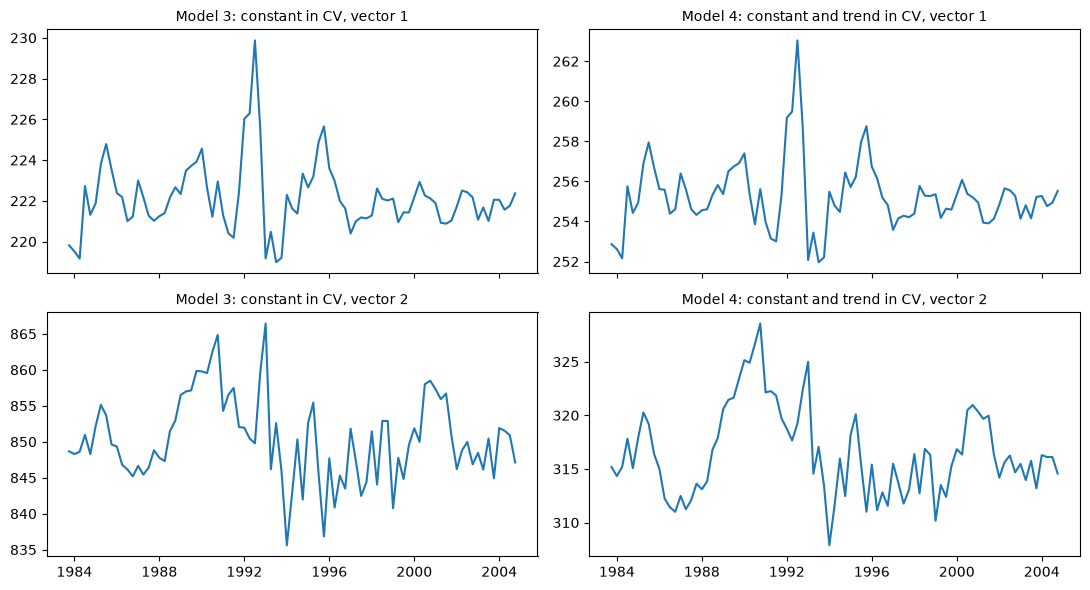

In [18]:
# Q8: estimate cointegration vectors in model 3 and model 4 (no dummies, see note)
import io, contextlib

r = 2                                   # plot the first two vectors
dates = result["Dates"].iloc[p:].reset_index(drop=True)
T_eff = len(y) - p
trend = np.arange(1, T_eff + 1)

fig, axs = plt.subplots(2, 2, figsize=(11, 6), sharex=True)

for col, (model, name) in enumerate([(3, "Model 3: constant in CV"),
                                      (4, "Model 4: constant and trend in CV")]):
    with contextlib.redirect_stdout(io.StringIO()):          # hide the long printout
        out = jcitestexog(y, p-1, 0, model)                  # [UÆNDRET funktion fra s_master]
    beta = np.real(np.array(out[5], dtype=complex))          # K x (K-1), one vector per column
    d0   = out[9]                                            # trend coefficients (model 4 only)

    for j in range(r):
        b = beta[:, j] / beta[ENDOG.index("i"), j]           # [EGEN KODE] normalise on i
        cv = y[p:, :] @ b                                    # beta_j' y_t
        if model == 4:
            cv = cv + np.real(d0[j]) / beta[ENDOG.index("i"), j] * trend   # add trend term
        axs[j, col].plot(dates, cv)
        axs[j, col].set_title(f"{name}, vector {j+1}", fontsize=10)
        print(f"Model {model}, vector {j+1} (normalised on i):",
              dict(zip(ENDOG, np.round(b, 3))))

plt.tight_layout()
plt.show()

### Q9
Test for the presence of a linear trend in the cointegration vector. Should a linear
trend be included or not?

In [36]:
model = 'H*'
lags  = float(p - 1)      # 2.0: VECM-lags for VAR(3)
alpha = 0.05
r     = 2.0               # rang fra trace-testen i model 4 uden dummies

test = ['bcon']
cons = np.transpose(np.array([[0, 0, 0, 0, 0, 1]], dtype=np.float64))   # H0: ingen trend i kointegrationsvektoren
LRtest, pval, dof, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, cons, model, lags, alpha)

Testing restrictions on β in VEC model with cointegration rank =  2 

The constraint on β tested is
 [[0.0000 0.0000 0.0000 0.0000 0.0000 1.0000]] 


LR test of restriction with 2 degrees of freedom
Lr test statistic = 1.5876
with p-value =  0.4521 

Restricted estimates of alpha and beta
     α1       α2        β1       β2
-------  -------  --------  -------
 0.0026  -0.0022  -12.3392  15.0809
 -0.002  -0.0001   63.1111  18.5863
 0.3231   0.1695   -0.8239   0.2622
 0.0575   -0.086   -0.0971   0.3637
-0.0064  -0.0072    15.686  45.2376

 Restricted estimates of deterministic terms 

      c0
--------
 182.108
-222.211

          c1
------------
   0.0114036
 -0.00361465
 0.000138767
-0.000622462
   0.0072789

  d0
----
   0
   0

  d1
----
 nan


We test H₀: ρ = 0 (no linear trend in the cointegration relations) in model H* with r = 2. The LR statistic is 1.59 with 2 degrees of freedom (p = 0.452), so we cannot reject the null. The trend can be excluded from the cointegration vectors, and we proceed with model H1 (a constant in the cointegration relations) in the following questions.

### Q10
In your preferred model from above, test for stationarity, exclusion and weak
exogeneity using either the Python function or the Matlab built-in function. Interpret
your result.

##### Test for stationarity

In [20]:
model = 'H1'
lags  = float(p - 1)      # 2.0
alpha = 0.05
r     = 2.0               # [VALG] begrund i rapporten, brug samme r i Q10 og Q11
K     = len(ENDOG)

test = ['bvec']
rows = []
for k, name in enumerate(ENDOG):
    e = np.zeros((K, 1))
    e[k, 0] = 1.0                                   # enhedsvektor: H0 = variablen er stationær
    LRtest, pval, dof, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, e, model, lags, alpha)
    rows.append([name, float(np.ravel(LRtest)[0]), float(np.ravel(dof)[0]), float(np.ravel(pval)[0])])

pd.DataFrame(rows, columns=["H0: stationary", "LR", "df", "p-value"]).set_index("H0: stationary").round(3)

Testing restrictions on β in VEC model with cointegration rank =  2 

The constraint on β tested is
 [[1.0000 0.0000 0.0000 0.0000 0.0000]] 


LR test of restriction with 3 degrees of freedom
Lr test statistic = 29.4847
with p-value =  0.0 

Restricted estimates of alpha and beta
     α1       α2    β1       β2
-------  -------  ----  -------
-0.0315   0.0027     1        0
 0.0282   -0.002     0  63.0066
-3.8523   0.3242     0  -0.8295
-0.7542   0.0567     0  -0.0925
 0.0781  -0.0064     0  15.8342

 Restricted estimates of deterministic terms 

     c0
-------
-12.566
26.9067

          c1
------------
  0.00659771
  -0.0116047
-3.31801e-05
-0.000775139
 -0.00227486

  d0
----
 nan

  d1
----
 nan
Testing restrictions on β in VEC model with cointegration rank =  2 

The constraint on β tested is
 [[0.0000 1.0000 0.0000 0.0000 0.0000]] 


LR test of restriction with 3 degrees of freedom
Lr test statistic = 16.2884
with p-value =  0.001 

Restricted estimates of alpha and beta
     α1 

,LR,df,p-value
H0: stationary,,,
y,29.485,3.0,0.000
pi,16.288,3.0,0.001
i,24.866,3.0,0.000
i_star,23.523,3.0,0.000
de,9.721,3.0,0.021


##### Test for exclusion

In [21]:
model = 'H1'
lags  = float(p - 1)      # 2.0
alpha = 0.05
r     = 2.0               # samme r som i stationaritetstesten
K     = len(ENDOG)

test = ['bcon']
rows = []
for k, name in enumerate(ENDOG):
    e = np.zeros((K, 1))
    e[k, 0] = 1.0                                   # enhedsvektor: H0 = variablen kan udelades fra alle kointegrationsvektorer
    LRtest, pval, dof, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, e, model, lags, alpha)
    rows.append([name, float(np.ravel(LRtest)[0]), float(np.ravel(dof)[0]), float(np.ravel(pval)[0])])

pd.DataFrame(rows, columns=["H0: excluded", "LR", "df", "p-value"]).set_index("H0: excluded").round(3)

Testing restrictions on β in VEC model with cointegration rank =  2 

The constraint on β tested is
 [[1.0000 0.0000 0.0000 0.0000 0.0000]] 


LR test of restriction with 2 degrees of freedom
Lr test statistic = 12.5972
with p-value =  0.0018 

Restricted estimates of alpha and beta
     α1       α2       β1       β2
-------  -------  -------  -------
 0.0007   0.0006        0        0
-0.0017   0.0015  61.4694  -7.1464
 0.3597  -0.0952  -0.4821   0.2116
-0.0083  -0.0016    0.148  -0.2674
-0.0093  -0.0085  38.9898  59.0089

 Restricted estimates of deterministic terms 

     c0
-------
1.41432
5.65317

         c1
-----------
 0.00117326
-0.00768182
-0.00258636
   -0.17885
  0.0610643

  d0
----
 nan

  d1
----
 nan
Testing restrictions on β in VEC model with cointegration rank =  2 

The constraint on β tested is
 [[0.0000 1.0000 0.0000 0.0000 0.0000]] 


LR test of restriction with 2 degrees of freedom
Lr test statistic = 15.9378
with p-value =  0.0003 

Restricted estimates of alpha

,LR,df,p-value
H0: excluded,,,
y,12.597,2.0,0.002
pi,15.938,2.0,0.000
i,14.412,2.0,0.001
i_star,1.855,2.0,0.395
de,4.754,2.0,0.093


##### Test for weak exogeneity

In [45]:
model = 'H1'
lags  = float(p - 1)      # 2.0
alpha = 0.05
r     = 2.0               # samme r som i stationaritetstesten
K     = len(ENDOG)

test = ['acon']
rows = []
for k, name in enumerate(ENDOG):
    e = np.zeros((K, 1))
    e[k, 0] = 1.0                                   # enhedsvektor: H0 = variablen tilpasser sig ikke ligevægten (svagt eksogen)
    LRtest, pval, dof, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y, r, test, e, model, lags, alpha)
    rows.append([name, float(np.ravel(LRtest)[0]), float(np.ravel(dof)[0]), float(np.ravel(pval)[0])])

pd.DataFrame(rows, columns=["H0: weakly exogenous", "LR", "df", "p-value"]).set_index("H0: weakly exogenous").round(3)

Testing restrictions on α in VEC model with cointegration rank =  2 

The constraint on α tested is
 [[1.0000 0.0000 0.0000 0.0000 0.0000]] 


LR test of restriction with 2 degrees of freedom
Lr test statistic = 11.1412
with p-value =  0.0038 

Restricted estimates of alpha and beta
     α1       α2       β1        β2
-------  -------  -------  --------
      0        0  -0.1076   10.4021
-0.0018   0.0022  62.5023  -23.6424
 0.3517  -0.0419  -0.4675      0.39
-0.0077  -0.0729   0.1248    0.2615
-0.0087  -0.0078  36.5957   61.1161

 Restricted estimates of deterministic terms 

      c0
--------
 1.78143
-151.873

         c1
-----------
 0.00478094
-0.00741309
0.000499765
-0.00312188
  0.0244876

  d0
----
 nan

  d1
----
 nan
Testing restrictions on α in VEC model with cointegration rank =  2 

The constraint on α tested is
 [[0.0000 1.0000 0.0000 0.0000 0.0000]] 


LR test of restriction with 2 degrees of freedom
Lr test statistic = 3.507
with p-value =  0.1732 

Restricted estimates

,LR,df,p-value
H0: weakly exogenous,,,
y,11.141,2.0,0.004
pi,3.507,2.0,0.173
i,10.511,2.0,0.005
i_star,6.048,2.0,0.049
de,5.769,2.0,0.056


### Q11
Bjørnland discusses in her paper possible cointegration vectors in the VAR system.
How should hypotheses concerning PPP and UIP be formulated? Conduct a test of the
implied cointegration vector(s). To gain further insights, provide a plot and discuss.

##### PPP

In [65]:
model = 'H1'
lags = float(p-1)
alpha = 0.05
r = 2.0

test = ['bvec']
cons = np.transpose(np.array([[0, 0, 0, 0, 1]], dtype=np.float64))  # Ensure it's a double
LRtest, pval, dof, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y,r,test,cons,model,lags,alpha)

Testing restrictions on β in VEC model with cointegration rank =  2 

The constraint on β tested is
 [[0.0000 0.0000 0.0000 0.0000 1.0000]] 


LR test of restriction with 3 degrees of freedom
Lr test statistic = 9.7209
with p-value =  0.0211 

Restricted estimates of alpha and beta
     α1       α2    β1        β2
-------  -------  ----  --------
 0.0769   0.0026     0  -12.9039
 0.0882  -0.0022     0   62.6613
  3.775   0.3175     0   -0.8376
-0.8231   0.0622     0   -0.1062
-0.6873  -0.0052     1         0

 Restricted estimates of deterministic terms 

       c0
---------
0.0777814
  190.191

        c1
----------
0.00331907
-0.0115507
0.00498286
-0.0215901
 0.0521123

  d0
----
 nan

  d1
----
 nan


##### UIP

In [70]:
model = 'H1'
lags = float(p-1)
alpha = 0.05
r = 2.0

test = ['bvec']
cons = np.transpose(np.array([[0, 0, 1, -1, -400]], dtype=np.float64))  # Ensure it's a double
LRtest, pval, dof, Arest, Brest, c0r, c1r, d0r, d1r = johcontest(y,r,test,cons,model,lags,alpha)

Testing restrictions on β in VEC model with cointegration rank =  2 

The constraint on β tested is
 [[0.0000 0.0000 1.0000 -1.0000 -400.0000]] 


LR test of restriction with 3 degrees of freedom
Lr test statistic = 10.7307
with p-value =  0.0133 

Restricted estimates of alpha and beta
     α1       α2    β1        β2
-------  -------  ----  --------
-0.0002   0.0026     0  -13.0825
-0.0003  -0.0023     0   62.8298
-0.0135   0.3102     1   -0.8147
 0.0032   0.0654    -1   -0.1417
 0.0014  -0.0047  -400   -0.0017

 Restricted estimates of deterministic terms 

      c0
--------
-24.3016
 192.754

         c1
-----------
 0.00468152
 -0.0106103
 0.00175093
-0.00666979
  0.0304633

  d0
----
 nan

  d1
----
 nan


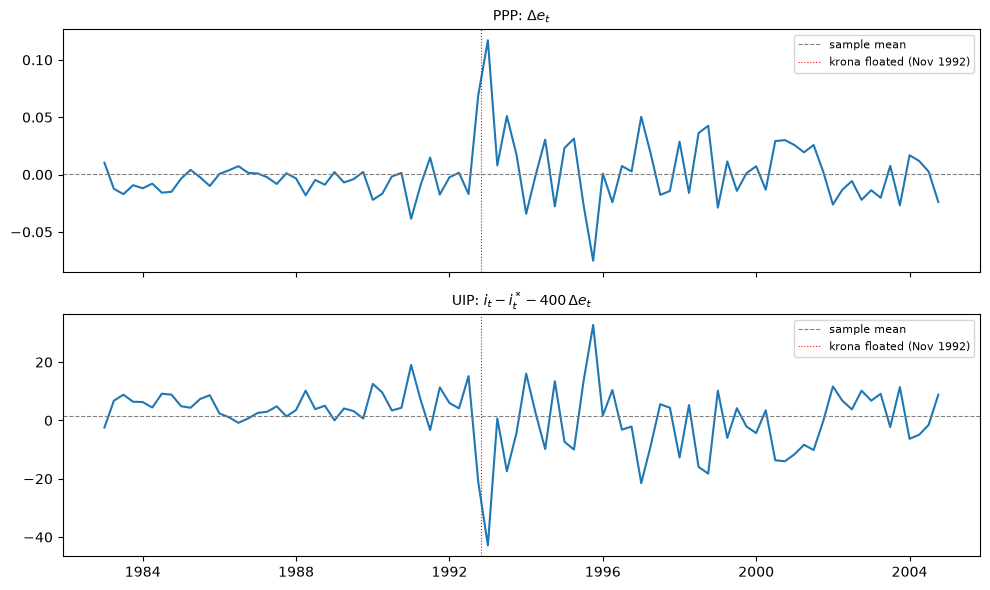

In [69]:
# Q11: theoretical cointegration relations implied by PPP and UIP
ppp = result["de"]                                              # beta = [0, 0, 0, 0, 1]
uip = result["i"] - result["i_star"] - 400 * result["de"]       # beta = [0, 0, 1, -1, -400]

fig, axs = plt.subplots(2, 1, figsize=(10, 6), sharex=True)

for ax, series, title in [(axs[0], ppp, r"PPP: $\Delta e_t$"),
                          (axs[1], uip, r"UIP: $i_t - i^*_t - 400\,\Delta e_t$")]:
    ax.plot(result["Dates"], series)
    ax.axhline(series.mean(), color="grey", lw=0.8, ls="--", label="sample mean")
    ax.axvline(pd.Timestamp("1992-11-01"), color="red", lw=0.8, ls=":", label="krona floated (Nov 1992)")
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig("q11_relations.png", dpi=300, bbox_inches="tight")
plt.show()